# Olist E-Commerce Analytics

**End-to-End Data Analytics Portfolio Project**

This notebook analyzes the historical Brazilian E-Commerce Public Dataset by Olist. It traces the full workflow from raw CSV files through data quality checks, logistics, customer satisfaction, sales analysis and Power BI-ready exports.

**Business questions**
- What is the scale and composition of delivered-product sales?
- Which states have the most delivery delays, and which have the highest delay rates?
- How are delivery delays associated with review scores?
- What data-quality limitations should decision-makers consider?

**Data scope:** Delivered orders are the population for the executive dashboard. Some logistics and satisfaction indicators exclude records with incomplete delivery or review data.

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, Jupyter and Power BI.

---

## 1. Environment and Data Loading

Install the requirements in `requirements.txt`. Place the nine original Olist CSVs inside `data/raw/` (recommended), or keep them in `~/Downloads/archive/`. Run the notebook from the repository root or the `notebooks/` directory. The source files are not embedded in this notebook.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
print("Analytics environment ready")


### 1.1 Portable project configuration

The notebook looks for the nine source CSVs in `data/raw/` first, then in `~/Downloads/archive/` (the original local Olist location). You may set `custom_data_dir` in the next cell for other locations. **CSV source files are read, not modified.** Processed exports are written separately to `data/processed/`.


In [ ]:
# Locate source datasets without changing any raw files.
# Preferred for a portable GitHub project: <project>/data/raw/.
# Local convenience fallback: ~/Downloads/archive/ (original Olist extraction).
# If your CSVs are elsewhere, set custom_data_dir to an existing folder path.
project_root = Path.cwd().resolve()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

custom_data_dir = None  # Example: Path(r"D:\datasets\olist")

required_datasets = [
    "olist_customers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv",
]

source_candidates = []
if custom_data_dir is not None:
    source_candidates.append(Path(custom_data_dir).expanduser())
source_candidates.extend([
    project_root / "data" / "raw",
    Path.home() / "Downloads" / "archive",
])

data_path = next(
    (directory for directory in source_candidates
     if all((directory / filename).is_file() for filename in required_datasets)),
    None,
)
if data_path is None:
    locations = "\n".join(f" - {folder}" for folder in source_candidates)
    raise FileNotFoundError(
        "The nine Olist CSV files were not found in any expected location.\n"
        f"Checked these folders:\n{locations}\n"
        "Extract the source CSVs to data/raw/ (recommended), or set "
        "custom_data_dir in this cell. See README.md."
    )

figures_path = project_root / "reports" / "figures"
figures_path.mkdir(parents=True, exist_ok=True)
csv_files = [data_path / filename for filename in required_datasets]
print(f"Data directory: {data_path}")
print(f"Datasets found: {len(csv_files)}")


### 1.2 Read the nine source datasets

Each CSV is loaded separately to preserve source-level granularity and auditability.

In [6]:

# Carregar todos os arquivos CSV
datasets = {}

for file in csv_files:
    name = file.stem
    datasets[name] = pd.read_csv(file)

# Mostrar dimensões de cada dataset
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} linhas | {df.shape[1]} colunas")

olist_customers_dataset: 99441 linhas | 5 colunas
olist_geolocation_dataset: 1000163 linhas | 5 colunas
olist_orders_dataset: 99441 linhas | 8 colunas
olist_order_items_dataset: 112650 linhas | 7 colunas
olist_order_payments_dataset: 103886 linhas | 5 colunas
olist_order_reviews_dataset: 99224 linhas | 7 colunas
olist_products_dataset: 32951 linhas | 9 colunas
olist_sellers_dataset: 3095 linhas | 4 colunas
product_category_name_translation: 71 linhas | 2 colunas


### 1.3 Initial source-data quality review

Examine row counts, column counts, missing values and full-row duplicates by dataset.

In [7]:
# Dataset Overview

summary = []

for name, df in datasets.items():
    summary.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,olist_customers_dataset,99441,5,0,0
1,olist_geolocation_dataset,1000163,5,0,261831
2,olist_orders_dataset,99441,8,4908,0
3,olist_order_items_dataset,112650,7,0,0
4,olist_order_payments_dataset,103886,5,0,0
5,olist_order_reviews_dataset,99224,7,145903,0
6,olist_products_dataset,32951,9,2448,0
7,olist_sellers_dataset,3095,4,0,0
8,product_category_name_translation,71,2,0,0


## 2. Orders: Quality Assessment and Date Preparation

Review order statuses, missing timestamps and whether datetime conversion introduces new null values.


In [9]:
# Criar uma cópia para análise
orders = datasets["olist_orders_dataset"].copy()

# Contagem dos pedidos por status
status_counts = orders["order_status"].value_counts()

display(status_counts)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [10]:
# Analisar valores ausentes por status do pedido

missing_by_status = orders.groupby("order_status").agg(
    total_orders=("order_id", "count"),

    missing_approval=(
        "order_approved_at",
        lambda x: x.isnull().sum()
    ),

    missing_carrier_date=(
        "order_delivered_carrier_date",
        lambda x: x.isnull().sum()
    ),

    missing_delivery_date=(
        "order_delivered_customer_date",
        lambda x: x.isnull().sum()
    )
)

display(missing_by_status)

,total_orders,missing_approval,missing_carrier_date,missing_delivery_date
order_status,,,,
approved,2,0,2,2
canceled,625,141,550,619
created,5,5,5,5
delivered,96478,14,2,8
invoiced,314,0,314,314
processing,301,0,301,301
shipped,1107,0,0,1107
unavailable,609,0,609,609


In [11]:
# Identificar colunas de datas
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Converter para datetime
for col in date_columns:
    orders[col] = pd.to_datetime(
        orders[col],
        errors="coerce"
    )

# Verificar os novos tipos
display(orders[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [12]:
# Valores ausentes antes da conversão
missing_before = datasets["olist_orders_dataset"][
    date_columns
].isnull().sum()

# Valores ausentes depois da conversão
missing_after = orders[
    date_columns
].isnull().sum()

# Comparar resultados
validation = pd.DataFrame({
    "Before Conversion": missing_before,
    "After Conversion": missing_after,
    "New Missing Values": missing_after - missing_before
})

display(validation)

,Before Conversion,After Conversion,New Missing Values
order_purchase_timestamp,0,0,0
order_approved_at,160,160,0
order_delivered_carrier_date,1783,1783,0
order_delivered_customer_date,2965,2965,0
order_estimated_delivery_date,0,0,0


### 2.1 Delivered-order records with incomplete timestamps

Inspect missing approval, carrier and delivery dates without discarding all delivered orders. The subsequent logistics calculation requires valid purchase and delivery dates.


In [14]:
# Identificar datas importantes
important_dates = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

# Filtrar pedidos entregues com informações ausentes
delivery_issues = orders[
    (orders["order_status"] == "delivered") &
    (orders[important_dates].isnull().any(axis=1))
].copy()

# Mostrar quantidade de pedidos afetados
print("Pedidos afetados:", len(delivery_issues))

# Mostrar valores ausentes por coluna
print("\nMissing Values:")
print(delivery_issues[important_dates].isnull().sum())

Pedidos afetados: 23

Missing Values:
order_approved_at                14
order_delivered_carrier_date      2
order_delivered_customer_date     8
dtype: int64


## 3. Delivery Performance

**Delivery time** is the elapsed time between purchase and actual delivery, measured in fractional days. The delivery-time analysis uses delivered orders with both timestamps present.

In [15]:
# Selecionar pedidos entregues com datas válidas
delivery_analysis = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_purchase_timestamp"].notna()) &
    (orders["order_delivered_customer_date"].notna())
].copy()

# Calcular o tempo de entrega em dias
delivery_analysis["delivery_days"] = (
    delivery_analysis["order_delivered_customer_date"] -
    delivery_analysis["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Verificar possíveis inconsistências
negative_days = (
    delivery_analysis["delivery_days"] < 0
).sum()

print("Pedidos disponíveis:", len(delivery_analysis))
print("Tempos de entrega negativos:", negative_days)

display(delivery_analysis[[
    "order_id",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "delivery_days"
]].head())

Pedidos disponíveis: 96470
Tempos de entrega negativos: 0


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2.873877


In [16]:
# Calcular indicadores de entrega
average_delivery = delivery_analysis["delivery_days"].mean()
median_delivery = delivery_analysis["delivery_days"].median()
max_delivery = delivery_analysis["delivery_days"].max()
min_delivery = delivery_analysis["delivery_days"].min()

print(f"Average Delivery Time: {average_delivery:.2f} days")
print(f"Median Delivery Time: {median_delivery:.2f} days")
print(f"Maximum Delivery Time: {max_delivery:.2f} days")
print(f"Minimum Delivery Time: {min_delivery:.2f} days")

Average Delivery Time: 12.56 days
Median Delivery Time: 10.22 days
Maximum Delivery Time: 209.63 days
Minimum Delivery Time: 0.53 days


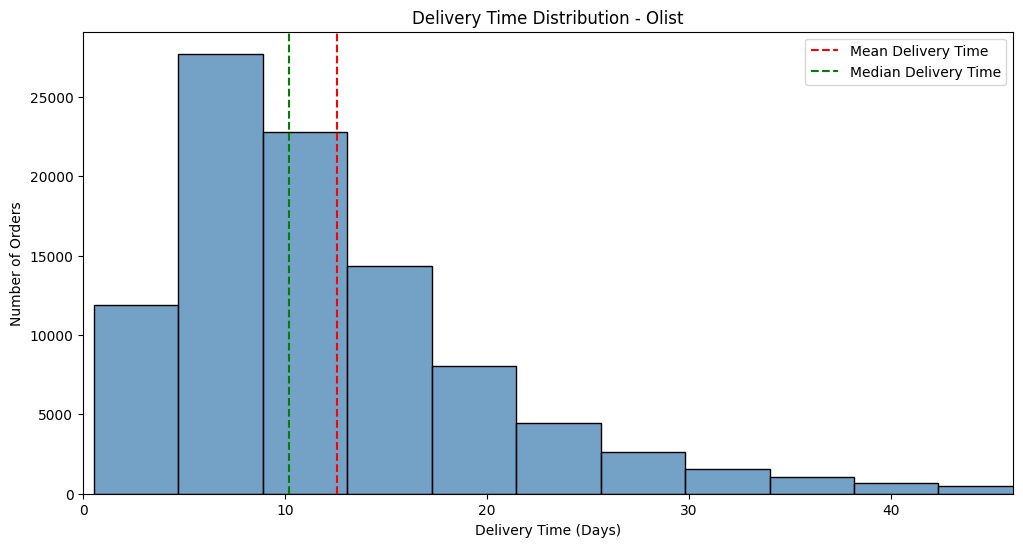

In [18]:

# Limite de visualização: percentil 99
p99 = delivery_analysis["delivery_days"].quantile(0.99)

# Criar gráfico
plt.figure(figsize=(12, 6))

sns.histplot(
    data=delivery_analysis,
    x="delivery_days",
    bins=50,
    color="steelblue"
)

plt.xlim(0, p99)

plt.axvline(
    delivery_analysis["delivery_days"].mean(),
    color="red",
    linestyle="--",
    label="Mean Delivery Time"
)

plt.axvline(
    delivery_analysis["delivery_days"].median(),
    color="green",
    linestyle="--",
    label="Median Delivery Time"
)

plt.title("Delivery Time Distribution - Olist")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.legend()

plt.show()

### 3.1 Estimated-versus-actual delivery delays

**Delay days** compares calendar dates rather than clock times. A delivery is late when its actual delivery date is after its estimated date.

In [19]:
# Criar uma cópia para analisar atrasos
late_delivery = delivery_analysis.copy()

# Comparar apenas a data, sem considerar o horário
late_delivery["delay_days"] = (
    late_delivery["order_delivered_customer_date"].dt.normalize()
    -
    late_delivery["order_estimated_delivery_date"].dt.normalize()
).dt.days

# Identificar pedidos atrasados
late_delivery["is_late"] = late_delivery["delay_days"] > 0

# Visualizar resultados
display(late_delivery[
    [
        "order_id",
        "order_estimated_delivery_date",
        "order_delivered_customer_date",
        "delay_days",
        "is_late"
    ]
].head(10))

,order_id,order_estimated_delivery_date,order_delivered_customer_date,delay_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-18,2017-10-10 21:25:13,-8,False
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-13,2018-08-07 15:27:45,-6,False
2,47770eb9100c2d0c44946d9cf07ec65d,2018-09-04,2018-08-17 18:06:29,-18,False
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-15,2017-12-02 00:28:42,-13,False
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-26,2018-02-16 18:17:02,-10,False
5,a4591c265e18cb1dcee52889e2d8acc3,2017-08-01,2017-07-26 10:57:55,-6,False
7,6514b8ad8028c9f2cc2374ded245783f,2017-06-07,2017-05-26 12:55:51,-12,False
8,76c6e866289321a7c93b82b54852dc33,2017-03-06,2017-02-02 14:08:10,-32,False
9,e69bfb5eb88e0ed6a785585b27e16dbf,2017-08-23,2017-08-16 17:14:30,-7,False
10,e6ce16cb79ec1d90b1da9085a6118aeb,2017-06-07,2017-05-29 11:18:31,-9,False


In [20]:
# Total de pedidos analisados
total_deliveries = len(late_delivery)

# Pedidos atrasados
late_orders = late_delivery["is_late"].sum()

# Pedidos entregues no prazo
on_time_orders = total_deliveries - late_orders

# Percentual de atraso
late_delivery_rate = (
    late_orders / total_deliveries
) * 100

# Resultados
print(f"Total Deliveries: {total_deliveries}")
print(f"Late Deliveries: {late_orders}")
print(f"On-Time Deliveries: {on_time_orders}")
print(f"Late Delivery Rate: {late_delivery_rate:.2f}%")

Total Deliveries: 96470
Late Deliveries: 6534
On-Time Deliveries: 89936
Late Delivery Rate: 6.77%


## 4. Regional Logistics Analysis

Join customer states, measure delay volume and rates, and compare operational risk across regions. The state-level summary excludes states with fewer than 100 valid deliveries.

In [21]:
# Customer geographic information
customers = datasets["olist_customers_dataset"][
    ["customer_id", "customer_state"]
].copy()

# Verificar duplicações na chave
print("Customer IDs duplicados:",
      customers["customer_id"].duplicated().sum())

# Realizar JOIN
delivery_by_state = late_delivery.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Verificar resultado
print("Total de registros:", len(delivery_by_state))
print("Pedidos sem estado:",
      delivery_by_state["customer_state"].isna().sum())

display(delivery_by_state.head())

Customer IDs duplicados: 0
Total de registros: 96470
Pedidos sem estado: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days,is_late,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,-8,False,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,-6,False,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,-18,False,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,-13,False,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,-10,False,SP


In [22]:
# Calcular indicadores por estado
state_summary = delivery_by_state.groupby(
    "customer_state"
).agg(
    total_deliveries=("order_id", "count"),
    late_deliveries=("is_late", "sum"),
    avg_delivery_days=("delivery_days", "mean")
).reset_index()

# Calcular percentual de atraso
state_summary["late_delivery_rate"] = (
    state_summary["late_deliveries"] /
    state_summary["total_deliveries"]
) * 100

# Considerar estados com pelo menos 100 entregas
state_summary = state_summary[
    state_summary["total_deliveries"] >= 100
]

# Ordenar por maior taxa de atraso
state_summary = state_summary.sort_values(
    by="late_delivery_rate",
    ascending=False
)

display(state_summary.round(2))

,customer_state,total_deliveries,late_deliveries,avg_delivery_days,late_delivery_rate
1,AL,397,85,24.54,21.41
9,MA,717,125,21.57,17.43
24,SE,335,51,21.52,15.22
16,PI,476,66,19.46,13.87
5,CE,1279,176,21.27,13.76
4,BA,3256,396,19.34,12.16
18,RJ,12350,1495,15.31,12.11
13,PA,946,106,23.77,11.21
7,ES,1995,214,15.79,10.73
14,PB,517,54,20.43,10.44


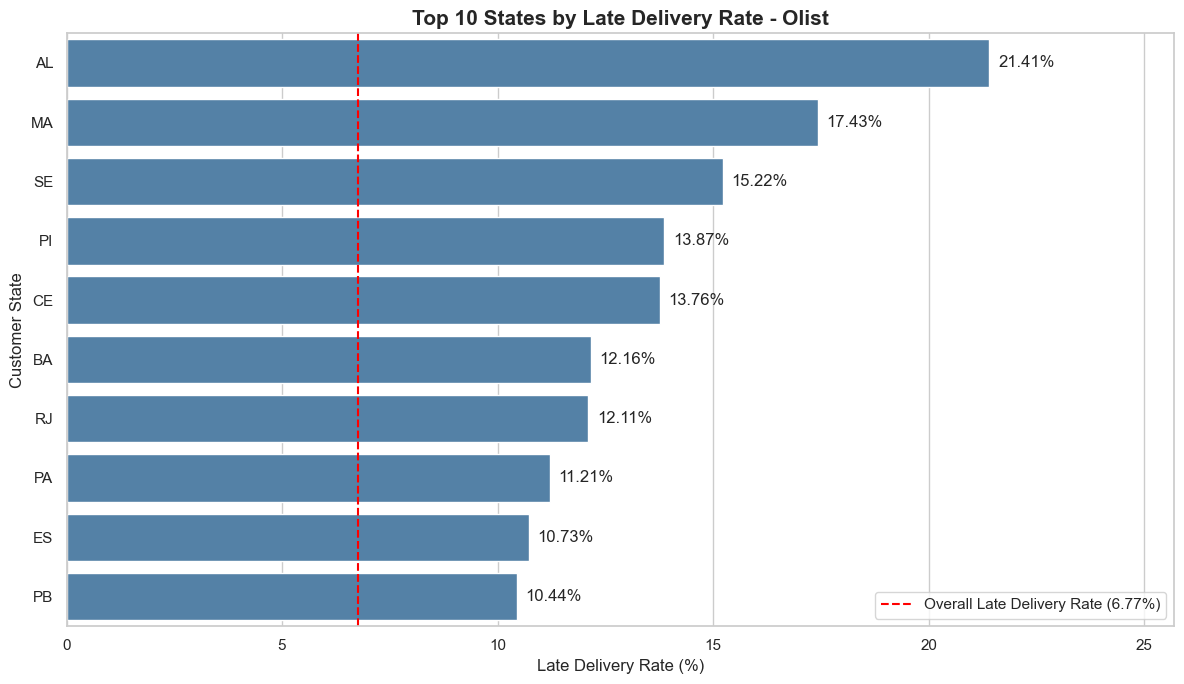

In [23]:

# Selecionar os 10 estados com maiores taxas de atraso
top_10_states = state_summary.nlargest(
    10, "late_delivery_rate"
)

# Configurar estilo
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 7))

# Criar gráfico
ax = sns.barplot(
    data=top_10_states,
    x="late_delivery_rate",
    y="customer_state",
    color="steelblue"
)

# Adicionar a média nacional
plt.axvline(
    late_delivery_rate,
    color="red",
    linestyle="--",
    label=f"Overall Late Delivery Rate ({late_delivery_rate:.2f}%)"
)

# Títulos
plt.title(
    "Top 10 States by Late Delivery Rate - Olist",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Customer State")

# Adicionar os percentuais às barras
for i, rate in enumerate(top_10_states["late_delivery_rate"]):
    ax.text(
        rate + 0.2,
        i,
        f"{rate:.2f}%",
        va="center"
    )

plt.xlim(0, top_10_states["late_delivery_rate"].max() * 1.2)

plt.legend()
plt.tight_layout()
plt.show()

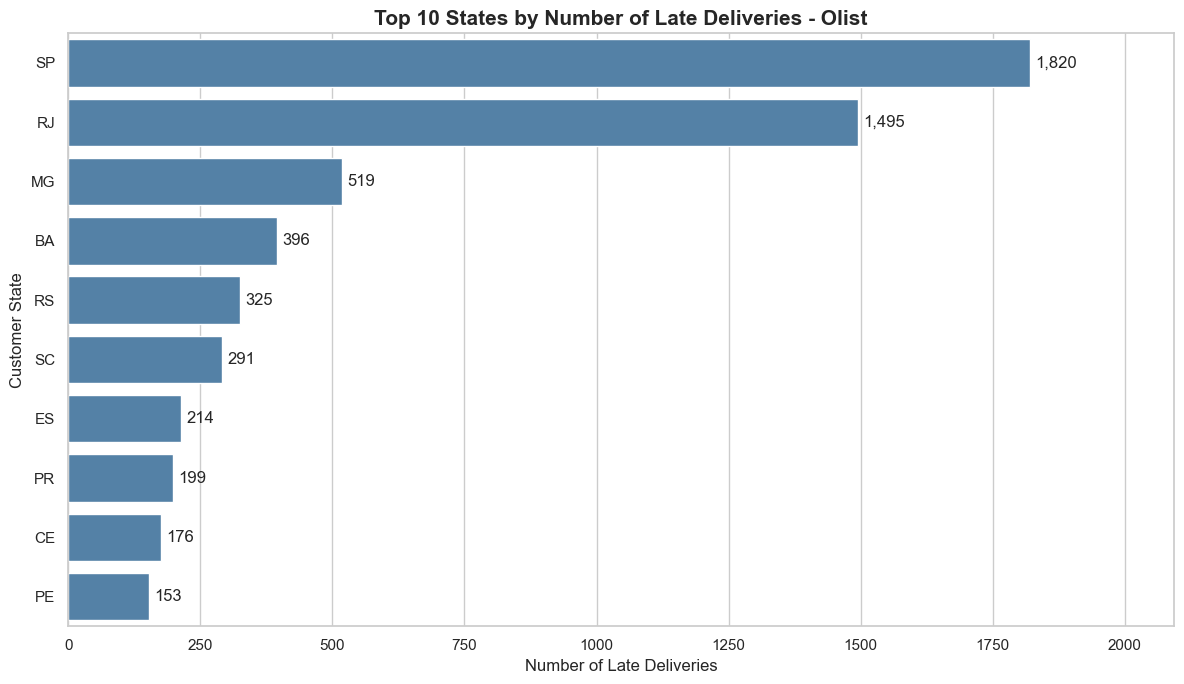

In [24]:
# Top 10 states by number of late deliveries
top_late_orders = state_summary.nlargest(
    10, "late_deliveries"
)

# Create visualization
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_late_orders,
    x="late_deliveries",
    y="customer_state",
    color="steelblue"
)

# Add values to bars
for i, value in enumerate(top_late_orders["late_deliveries"]):
    ax.text(
        value + 10,
        i,
        f"{value:,}",
        va="center"
    )

plt.title(
    "Top 10 States by Number of Late Deliveries - Olist",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Late Deliveries")
plt.ylabel("Customer State")

plt.xlim(
    0,
    top_late_orders["late_deliveries"].max() * 1.15
)

plt.tight_layout()
plt.show()

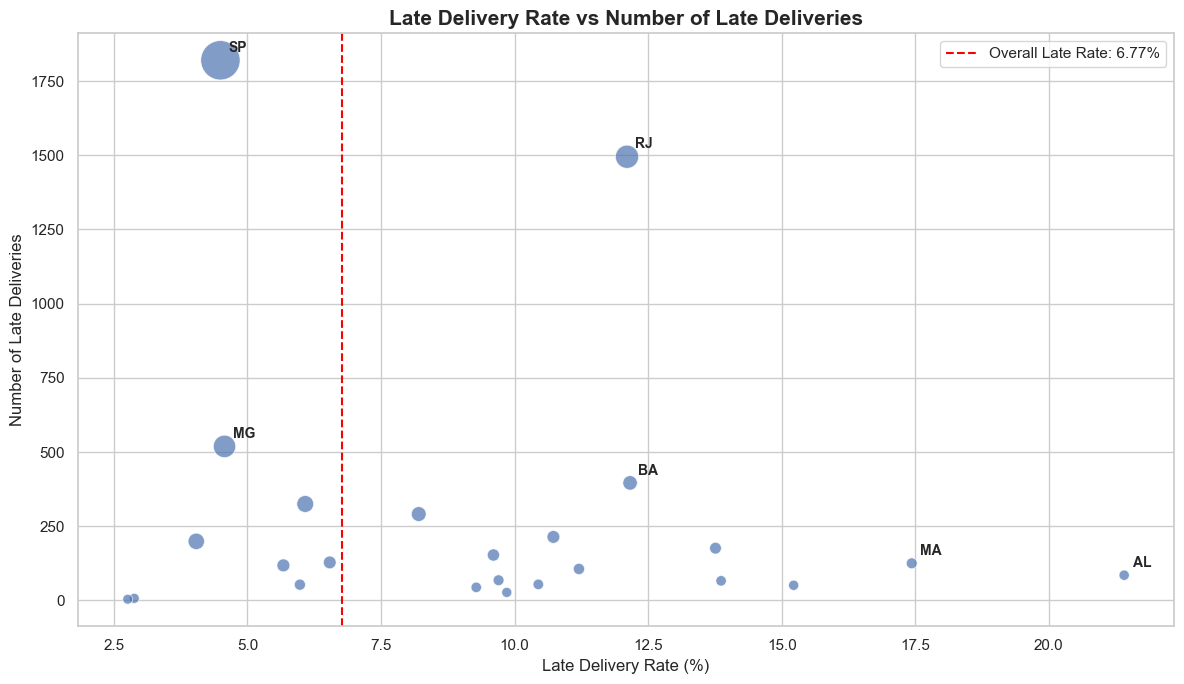

In [25]:

# Criar gráfico de dispersão
plt.figure(figsize=(12, 7))

ax = sns.scatterplot(
    data=state_summary,
    x="late_delivery_rate",
    y="late_deliveries",
    size="total_deliveries",
    sizes=(50, 800),
    alpha=0.7,
    legend=False
)

# Destacar estados importantes
highlight_states = ["SP", "RJ", "AL", "MA", "MG", "BA"]

for _, row in state_summary.iterrows():
    if row["customer_state"] in highlight_states:
        plt.annotate(
            row["customer_state"],
            (
                row["late_delivery_rate"],
                row["late_deliveries"]
            ),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold"
        )

# Referência da taxa geral
plt.axvline(
    late_delivery_rate,
    color="red",
    linestyle="--",
    label=f"Overall Late Rate: {late_delivery_rate:.2f}%"
)

plt.title(
    "Late Delivery Rate vs Number of Late Deliveries",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Number of Late Deliveries")

plt.legend()
plt.tight_layout()
plt.show()

**Logistics interpretation.** In the recorded run, 96,470 delivered orders had valid purchase and delivery timestamps. Of those, 6,534 were late (6.77%). São Paulo had the highest absolute number of late deliveries (1,820), while Alagoas had the highest state-level late rate (21.41%) in the sample-size-filtered comparison. Volume and rate answer different business questions.

## 5. Review-Data Audit and Consolidation

Multiple review records can belong to a single order. To prevent join inflation, aggregate review scores to the order level before merging with deliveries.

In [ ]:
# Review records: basic source-data checks
reviews = datasets["olist_order_reviews_dataset"].copy()
print(f"Review records: {len(reviews):,}")
print(f"Orders represented: {reviews['order_id'].nunique():,}")
print("Missing review scores:", reviews["review_score"].isna().sum())
print("Duplicate review IDs:", reviews["review_id"].duplicated().sum())


In [ ]:
# Explain why reviews are consolidated before joining to orders.
review_counts = reviews.groupby("order_id").size()
print("Orders with more than one review:", (review_counts > 1).sum())
print("Completely duplicate review rows:", reviews.duplicated().sum())


### 5.1 One review summary per order

The mean preserves fractional review scores for orders with multiple ratings. This is important when calculating low-rating rates.

In [31]:
# Customer Reviews - Data Aggregation

reviews_clean = reviews.groupby(
    "order_id",
    as_index=False
).agg(
    avg_review_score=("review_score", "mean"),
    review_count=("review_score", "count"),
    unique_scores=("review_score", "nunique")
)

# Identificar pedidos com notas diferentes
reviews_clean["conflicting_scores"] = (
    reviews_clean["unique_scores"] > 1
)

# Verificar resultado
print("Original Reviews:", len(reviews))
print("Unique Orders:", len(reviews_clean))

print(
    "Duplicate Order IDs:",
    reviews_clean["order_id"].duplicated().sum()
)

print(
    "Orders with Conflicting Scores:",
    reviews_clean["conflicting_scores"].sum()
)

display(reviews_clean.head(10))

Original Reviews: 99224
Unique Orders: 98673
Duplicate Order IDs: 0
Orders with Conflicting Scores: 202


,order_id,avg_review_score,review_count,unique_scores,conflicting_scores
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,1,1,False
1,00018f77f2f0320c557190d7a144bdd3,4.0,1,1,False
2,000229ec398224ef6ca0657da4fc703e,5.0,1,1,False
3,00024acbcdf0a6daa1e931b038114c75,4.0,1,1,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,1,1,False
5,00048cc3ae777c65dbb7d2a0634bc1ea,4.0,1,1,False
6,00054e8431b9d7675808bcb819fb4a32,4.0,1,1,False
7,000576fe39319847cbb9d288c5617fa6,5.0,1,1,False
8,0005a1a1728c9d785b8e2b08b904576c,1.0,1,1,False
9,0005f50442cb953dcd1d21e1fb923495,4.0,1,1,False


### 5.2 Join reviews to the delivery analysis

Use a one-to-one merge and verify that the delivery row count is unchanged.

In [32]:
# Merge Delivery and Customer Reviews

delivery_reviews = late_delivery.merge(
    reviews_clean,
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Data validation
print("Original Deliveries:", len(late_delivery))
print("Records After JOIN:", len(delivery_reviews))

print(
    "Orders Without Reviews:",
    delivery_reviews["avg_review_score"].isna().sum()
)

display(
    delivery_reviews[
        [
            "order_id",
            "delivery_days",
            "delay_days",
            "is_late",
            "avg_review_score",
            "review_count"
        ]
    ].head(10)
)

Original Deliveries: 96470
Records After JOIN: 96470
Orders Without Reviews: 646


,order_id,delivery_days,delay_days,is_late,avg_review_score,review_count
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,-8,False,4.0,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,-6,False,4.0,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,-18,False,5.0,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,-13,False,5.0,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,-10,False,5.0,1.0
5,a4591c265e18cb1dcee52889e2d8acc3,16.542245,-6,False,4.0,1.0
6,6514b8ad8028c9f2cc2374ded245783f,9.989826,-12,False,5.0,1.0
7,76c6e866289321a7c93b82b54852dc33,9.818762,-32,False,1.0,1.0
8,e69bfb5eb88e0ed6a785585b27e16dbf,18.221852,-7,False,5.0,1.0
9,e6ce16cb79ec1d90b1da9085a6118aeb,12.650937,-9,False,1.0,1.0


## 6. Customer Satisfaction and Delivery Reliability

**Low rating:** an order-level average review score of 2 or lower (out of 5). Only orders with a recorded review enter rating-related denominators.

In [33]:
# Customer Satisfaction vs Delivery Performance

# Selecionar apenas pedidos com avaliações
reviewed_deliveries = delivery_reviews.dropna(
    subset=["avg_review_score"]
).copy()

# Comparar avaliações por situação da entrega
satisfaction_summary = reviewed_deliveries.groupby(
    "is_late"
).agg(
    total_orders=("order_id", "count"),
    average_review_score=("avg_review_score", "mean"),
    median_review_score=("avg_review_score", "median")
).reset_index()

# Renomear os grupos para facilitar a leitura
satisfaction_summary["delivery_status"] = (
    satisfaction_summary["is_late"].map({
        False: "On-Time",
        True: "Late"
    })
)

display(satisfaction_summary.round(2))

,is_late,total_orders,average_review_score,median_review_score,delivery_status
0,False,89443,4.29,5.0,On-Time
1,True,6381,2.27,1.0,Late


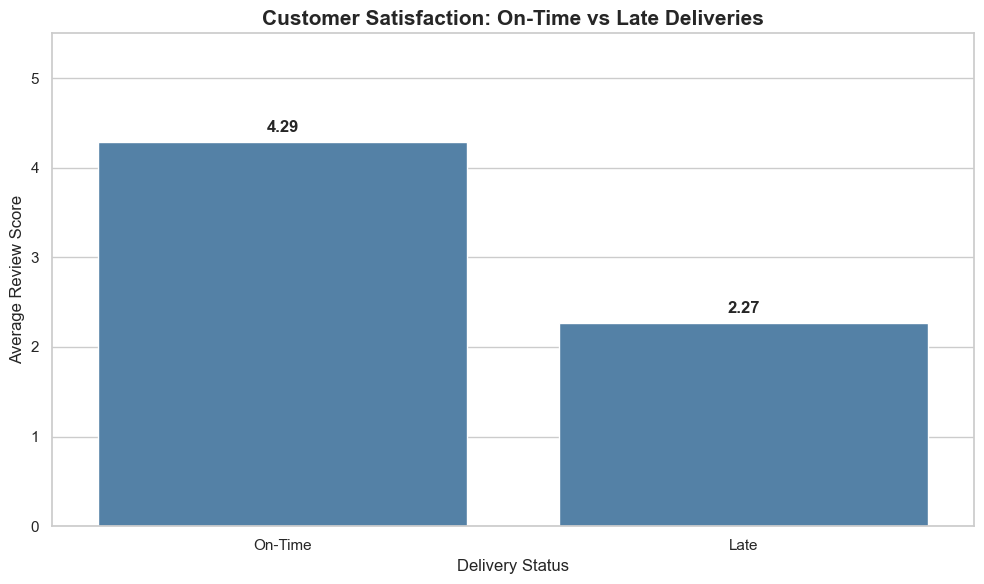

In [34]:

# Ordenar os grupos
order = ["On-Time", "Late"]

# Criar gráfico
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=satisfaction_summary,
    x="delivery_status",
    y="average_review_score",
    order=order,
    color="steelblue"
)

# Adicionar valores nas barras
for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points"
    )

# Configurações
plt.title(
    "Customer Satisfaction: On-Time vs Late Deliveries",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")

plt.ylim(0, 5.5)

plt.tight_layout()
plt.show()

### 6.1 Review scores by duration of delay

Buckets: On-Time / Early, 1–3 days, 4–7 days, 8–14 days and 15+ days late.

In [35]:

# Criar categorias de atraso
reviewed_deliveries["delay_category"] = pd.cut(
    reviewed_deliveries["delay_days"],
    bins=[float("-inf"), 0, 3, 7, 14, float("inf")],
    labels=[
        "On-Time / Early",
        "1-3 Days Late",
        "4-7 Days Late",
        "8-14 Days Late",
        "15+ Days Late"
    ]
)

# Calcular indicadores por categoria
delay_satisfaction = (
    reviewed_deliveries
    .groupby("delay_category", observed=True)
    .agg(
        total_orders=("order_id", "count"),
        average_score=("avg_review_score", "mean"),
        median_score=("avg_review_score", "median")
    )
    .reset_index()
)

display(delay_satisfaction.round(2))

,delay_category,total_orders,average_score,median_score
0,On-Time / Early,89443,4.29,5.0
1,1-3 Days Late,1852,3.29,4.0
2,4-7 Days Late,1748,2.11,1.0
3,8-14 Days Late,1446,1.67,1.0
4,15+ Days Late,1335,1.73,1.0


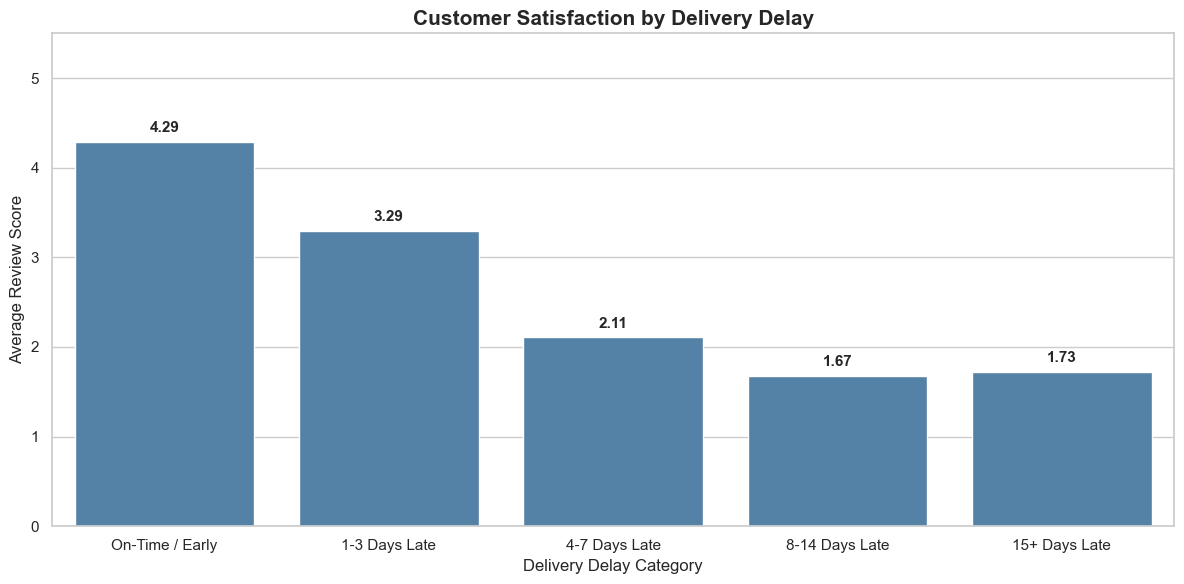

In [36]:

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=delay_satisfaction,
    x="delay_category",
    y="average_score",
    color="steelblue"
)

# Adicionar nota média nas barras
for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title(
    "Customer Satisfaction by Delivery Delay",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Delivery Delay Category")
plt.ylabel("Average Review Score")

plt.ylim(0, 5.5)

plt.tight_layout()
plt.show()

### 6.2 Percentage of low ratings by delay bucket

The numerator counts reviewed orders with an average score of 2 or less; the denominator counts reviewed orders in that delay bucket.

In [37]:
# Identificar avaliações baixas
reviewed_deliveries["low_rating"] = (
    reviewed_deliveries["avg_review_score"] <= 2
)

# Calcular indicadores por categoria de atraso
negative_review_summary = (
    reviewed_deliveries
    .groupby("delay_category", observed=True)
    .agg(
        total_orders=("order_id", "count"),
        low_rating_orders=("low_rating", "sum"),
        avg_review_score=("avg_review_score", "mean")
    )
    .reset_index()
)

# Calcular percentual de avaliações baixas
negative_review_summary["low_rating_rate"] = (
    negative_review_summary["low_rating_orders"] /
    negative_review_summary["total_orders"]
) * 100

display(negative_review_summary.round(2))

,delay_category,total_orders,low_rating_orders,avg_review_score,low_rating_rate
0,On-Time / Early,89443,8257,4.29,9.23
1,1-3 Days Late,1852,596,3.29,32.18
2,4-7 Days Late,1748,1181,2.11,67.56
3,8-14 Days Late,1446,1158,1.67,80.08
4,15+ Days Late,1335,1044,1.73,78.20


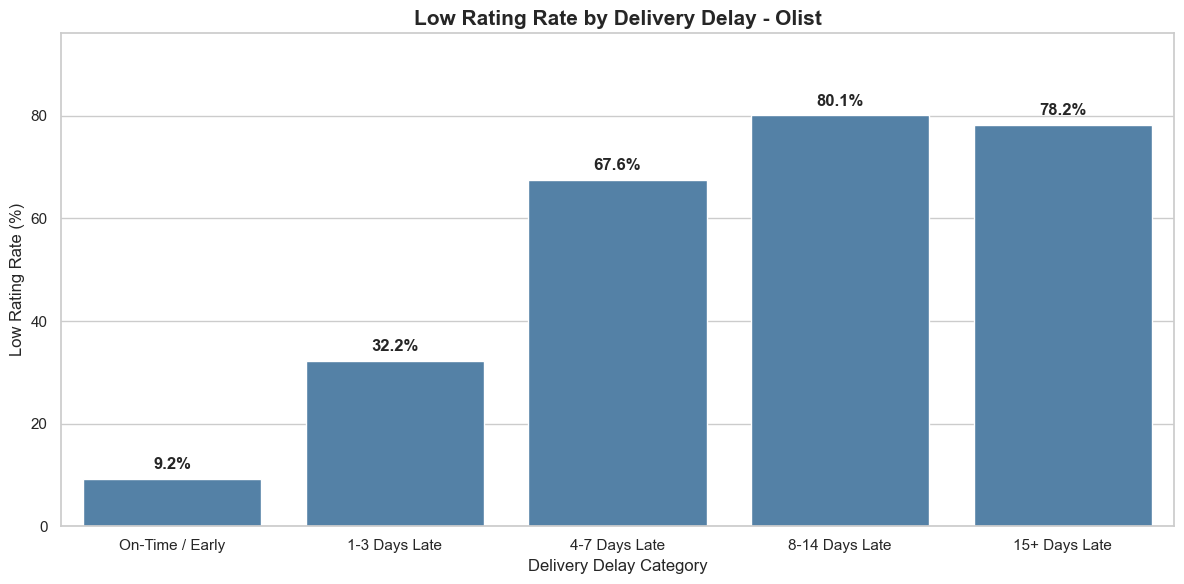

In [38]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=negative_review_summary,
    x="delay_category",
    y="low_rating_rate",
    color="steelblue"
)

# Adicionar percentuais
for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.1f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title(
    "Low Rating Rate by Delivery Delay - Olist",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Delivery Delay Category")
plt.ylabel("Low Rating Rate (%)")

plt.ylim(
    0,
    max(negative_review_summary["low_rating_rate"]) * 1.2
)

plt.tight_layout()
plt.show()

**Customer experience interpretation.** Orders delivered on time averaged 4.29 stars; late orders averaged 2.27 stars. The low-rating rate rose from 9.23% (on-time) to 62.36% (late), reaching 80.08% for delays of 8–14 days. These are associations, not causal estimates.

## 7. Sales and Payment Reconciliation

Order items and payment records can each contain several rows per order. Aggregate each table by `order_id` before reconciliation.

In [ ]:
# Load financial source tables; per-order reconciliation follows below.
order_items = datasets["olist_order_items_dataset"].copy()
payments = datasets["olist_order_payments_dataset"].copy()
print(f"Order-item rows: {len(order_items):,}; orders: {order_items['order_id'].nunique():,}")
print(f"Payment rows: {len(payments):,}; orders: {payments['order_id'].nunique():,}")


### 7.1 Aggregate line items and payment records

**Item total = product value + freight value.** Check for one-to-one order keys after aggregation.

In [41]:
# Aggregate Order Items by Order ID

items_summary = order_items.groupby(
    "order_id",
    as_index=False
).agg(
    total_items=("order_item_id", "count"),
    product_value=("price", "sum"),
    freight_value=("freight_value", "sum")
)

# Calculate total value
items_summary["items_total"] = (
    items_summary["product_value"] +
    items_summary["freight_value"]
)

# Validation
print("Original Item Records:", len(order_items))
print("Unique Orders:", len(items_summary))
print("Duplicate Order IDs:",
      items_summary["order_id"].duplicated().sum())

display(items_summary.head(10))

Original Item Records: 112650
Unique Orders: 98666
Duplicate Order IDs: 0


,order_id,total_items,product_value,freight_value,items_total
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,259.83
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,218.04
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,21.90,12.69,34.59
6,00054e8431b9d7675808bcb819fb4a32,1,19.90,11.85,31.75
7,000576fe39319847cbb9d288c5617fa6,1,810.00,70.75,880.75
8,0005a1a1728c9d785b8e2b08b904576c,1,145.95,11.65,157.60
9,0005f50442cb953dcd1d21e1fb923495,1,53.99,11.40,65.39


In [42]:
# Aggregate Payments by Order ID

payments_summary = payments.groupby(
    "order_id",
    as_index=False
).agg(
    payment_records=("payment_value", "count"),
    payment_total=("payment_value", "sum")
)

# Validation
print("Original Payment Records:", len(payments))
print("Unique Orders:", len(payments_summary))
print("Duplicate Order IDs:",
      payments_summary["order_id"].duplicated().sum())

display(payments_summary.head(10))

Original Payment Records: 103886
Unique Orders: 99440
Duplicate Order IDs: 0


,order_id,payment_records,payment_total
0,00010242fe8c5a6d1ba2dd792cb16214,1,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,259.83
2,000229ec398224ef6ca0657da4fc703e,1,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,218.04
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,34.59
6,00054e8431b9d7675808bcb819fb4a32,1,31.75
7,000576fe39319847cbb9d288c5617fa6,1,880.75
8,0005a1a1728c9d785b8e2b08b904576c,1,157.60
9,0005f50442cb953dcd1d21e1fb923495,1,65.39


### 7.2 Financial integrity review

Perform an outer join to identify orders missing from either side.

In [43]:
# Merge Financial Data

financial_data = items_summary.merge(
    payments_summary,
    on="order_id",
    how="outer",
    validate="one_to_one",
    indicator=True
)

# Validation
print("Orders in Items:", len(items_summary))
print("Orders in Payments:", len(payments_summary))
print("Orders After JOIN:", len(financial_data))

print("\nMerge Results:")
display(financial_data["_merge"].value_counts())

display(financial_data.head(10))

Orders in Items: 98666
Orders in Payments: 99440
Orders After JOIN: 99441

Merge Results:


_merge
both          98665
right_only      775
left_only         1
Name: count, dtype: int64

,order_id,total_items,product_value,freight_value,items_total,payment_records,payment_total,_merge
0,00010242fe8c5a6d1ba2dd792cb16214,1.0,58.90,13.29,72.19,1.0,72.19,both
1,00018f77f2f0320c557190d7a144bdd3,1.0,239.90,19.93,259.83,1.0,259.83,both
2,000229ec398224ef6ca0657da4fc703e,1.0,199.00,17.87,216.87,1.0,216.87,both
3,00024acbcdf0a6daa1e931b038114c75,1.0,12.99,12.79,25.78,1.0,25.78,both
4,00042b26cf59d7ce69dfabb4e55b4fd9,1.0,199.90,18.14,218.04,1.0,218.04,both
5,00048cc3ae777c65dbb7d2a0634bc1ea,1.0,21.90,12.69,34.59,1.0,34.59,both
6,00054e8431b9d7675808bcb819fb4a32,1.0,19.90,11.85,31.75,1.0,31.75,both
7,000576fe39319847cbb9d288c5617fa6,1.0,810.00,70.75,880.75,1.0,880.75,both
8,0005a1a1728c9d785b8e2b08b904576c,1.0,145.95,11.65,157.60,1.0,157.60,both
9,0005f50442cb953dcd1d21e1fb923495,1.0,53.99,11.40,65.39,1.0,65.39,both


In [45]:
# Financial Data Quality - Order Status Investigation

financial_audit = financial_data.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Comparar origem dos registros e status dos pedidos
status_audit = pd.crosstab(
    financial_audit["_merge"],
    financial_audit["order_status"]
)

display(status_audit)

order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable
_merge,,,,,,,,
left_only,0,0,0,1,0,0,0,0
right_only,0,164,5,0,2,0,1,603
both,2,461,0,96477,312,301,1106,6


### 7.3 Exact cent-based reconciliation

Round to integer cents to avoid floating-point noise. Count every nonzero-cent difference between payment amounts and item-plus-freight amounts, including one-cent discrepancies.


In [46]:
# Financial Reconciliation - Detailed Analysis

matched_orders = financial_data[
    financial_data["_merge"] == "both"
].copy()

# Convert values to cents
matched_orders["items_cents"] = (
    matched_orders["items_total"] * 100
).round().astype("int64")

matched_orders["payment_cents"] = (
    matched_orders["payment_total"] * 100
).round().astype("int64")

# Difference in cents
matched_orders["difference_cents"] = (
    matched_orders["payment_cents"] -
    matched_orders["items_cents"]
)

# Summary
print("=== FINANCIAL RECONCILIATION ===")

print("Matched Orders:", len(matched_orders))

print(
    "Matching Values:",
    (matched_orders["difference_cents"] == 0).sum()
)

print(
    "Different Values:",
    (matched_orders["difference_cents"] != 0).sum()
)

print(
    "Payments Higher Than Items:",
    (matched_orders["difference_cents"] > 0).sum()
)

print(
    "Payments Lower Than Items:",
    (matched_orders["difference_cents"] < 0).sum()
)

print(
    "Total Difference (R$):",
    round(matched_orders["difference_cents"].sum() / 100, 2)
)

=== FINANCIAL RECONCILIATION ===
Matched Orders: 98665
Matching Values: 98089
Different Values: 576
Payments Higher Than Items: 367
Payments Lower Than Items: 209
Total Difference (R$): 2870.39


In [47]:
# Financial Differences by Order Status

financial_check = matched_orders.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Agrupar inconsistências por status
differences_by_status = financial_check.groupby(
    "order_status"
).agg(
    total_orders=("order_id", "count"),

    orders_with_difference=(
        "difference_cents",
        lambda x: (x != 0).sum()
    ),

    net_difference_cents=(
        "difference_cents",
        "sum"
    )
).reset_index()

# Calcular taxa de inconsistência
differences_by_status["difference_rate"] = (
    differences_by_status["orders_with_difference"] /
    differences_by_status["total_orders"]
) * 100

# Converter diferença para reais
differences_by_status["net_difference_brl"] = (
    differences_by_status["net_difference_cents"] / 100
)

# Organizar resultados
differences_by_status = differences_by_status.sort_values(
    "orders_with_difference",
    ascending=False
)

display(differences_by_status.round(2))

,order_status,total_orders,orders_with_difference,net_difference_cents,difference_rate,net_difference_brl
2,delivered,96477,569,283148,0.59,2831.48
5,shipped,1106,4,689,0.36,6.89
1,canceled,461,2,3201,0.43,32.01
3,invoiced,312,1,1,0.32,0.01
0,approved,2,0,0,0.00,0.00
4,processing,301,0,0,0.00,0.00
6,unavailable,6,0,0,0.00,0.00


**Financial reconciliation note.** In the recorded analysis, 576 orders had nonzero differences (measured in cents) between registered payment amounts and the corresponding product-plus-freight totals. Such differences warrant investigation; the dataset alone does not establish their causes.


## 8. Delivered-Order Sales Analysis

**Total Product Value:** sum of product prices from delivered orders, excluding freight. **Average Order Value:** mean products-plus-freight total per delivered order. These metrics have different definitions and should not be confused with payment totals.

In [48]:
# Sales Performance - Delivered Orders

# Selecionar pedidos entregues
delivered_sales = orders[
    orders["order_status"] == "delivered"
][
    ["order_id", "order_purchase_timestamp"]
].copy()

# Relacionar com os valores dos produtos
delivered_sales = delivered_sales.merge(
    items_summary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validar dados
print("Delivered Orders:", len(delivered_sales))

print(
    "Orders Without Item Values:",
    delivered_sales["product_value"].isna().sum()
)

# Calcular KPIs
total_product_sales = delivered_sales["product_value"].sum()

total_freight = delivered_sales["freight_value"].sum()

average_order_value = delivered_sales["items_total"].mean()

print("\n=== SALES PERFORMANCE ===")

print(f"Total Product Value: R$ {total_product_sales:,.2f}")
print(f"Total Freight Value: R$ {total_freight:,.2f}")
print(f"Average Order Value (Products + Freight): R$ {average_order_value:,.2f}")

Delivered Orders: 96478
Orders Without Item Values: 0

=== SALES PERFORMANCE ===
Total Product Value: R$ 13,221,498.11
Total Freight Value: R$ 2,198,275.64
Average Order Value (Products + Freight): R$ 159.83


In [49]:
# Find delivered orders without payment records

unmatched_delivered = financial_audit[
    (financial_audit["_merge"] == "left_only") &
    (financial_audit["order_status"] == "delivered")
]

display(unmatched_delivered[
    ["order_id", "items_total", "payment_total", "order_status"]
])

,order_id,items_total,payment_total,order_status
74448,bfbd0f9bdef84302105ad712db648a6c,143.46,NaN,delivered


### 8.1 Monthly product sales

Aggregate delivered orders by their purchase month. The line chart visualizes historical monthly product value.

In [50]:
# Monthly Sales Performance Analysis

# Create Year-Month column
delivered_sales["year_month"] = (
    delivered_sales["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Aggregate monthly sales
monthly_sales = delivered_sales.groupby(
    "year_month"
).agg(
    total_orders=("order_id", "nunique"),
    product_sales=("product_value", "sum"),
    freight_total=("freight_value", "sum"),
    average_order_value=("items_total", "mean")
).reset_index()

# Convert month to string for visualization
monthly_sales["year_month"] = (
    monthly_sales["year_month"].astype(str)
)

# Display results
display(monthly_sales.round(2))

,year_month,total_orders,product_sales,freight_total,average_order_value
0,2016-09,1,134.97,8.49,143.46
1,2016-10,265,40325.11,6165.55,175.44
2,2016-12,1,10.90,8.72,19.62
3,2017-01,750,111798.36,15684.01,169.98
4,2017-02,1653,234223.40,37015.92,164.09
5,2017-03,2546,359198.85,55132.10,162.74
6,2017-04,2303,340669.68,50142.72,169.70
7,2017-05,3546,489338.25,77513.15,159.86
8,2017-06,3135,421923.37,68127.00,156.32
9,2017-07,3872,481604.52,84694.56,146.25


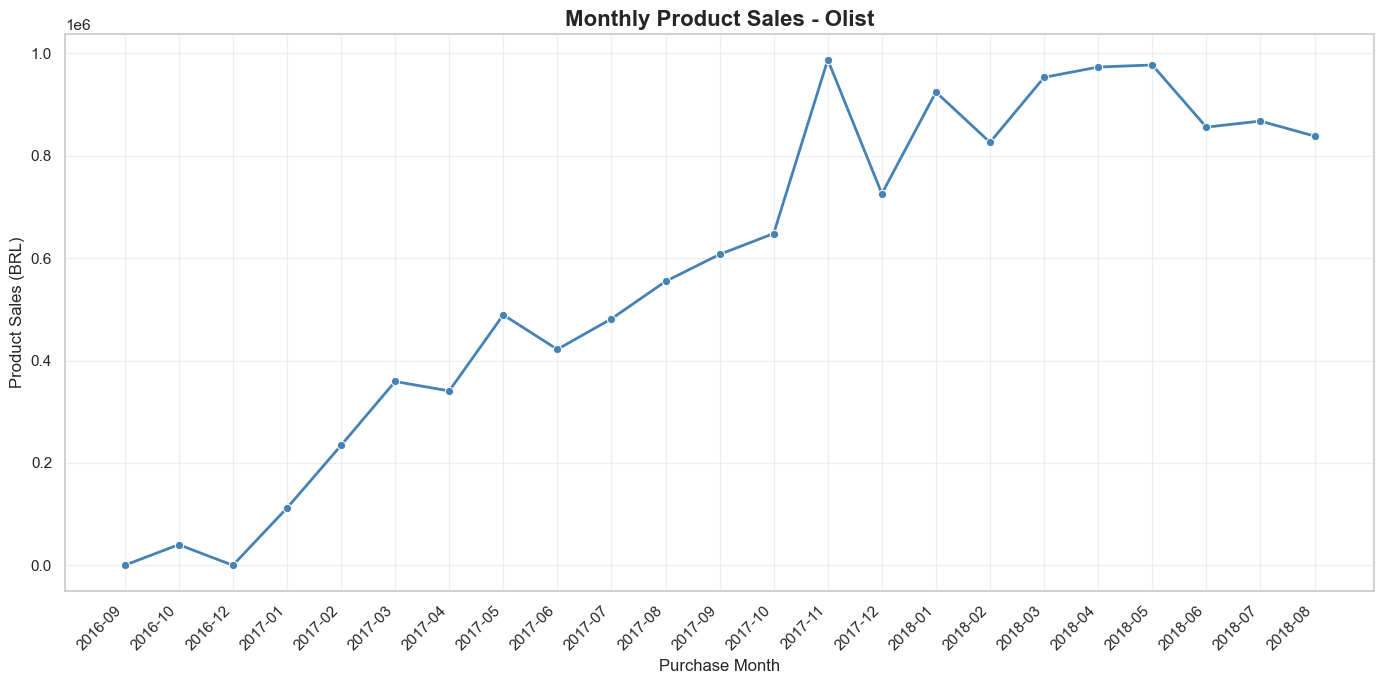

In [51]:

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=monthly_sales,
    x="year_month",
    y="product_sales",
    marker="o",
    linewidth=2,
    color="steelblue"
)

plt.title(
    "Monthly Product Sales - Olist",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Purchase Month")
plt.ylabel("Product Sales (BRL)")

plt.xticks(rotation=45, ha="right")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### 8.2 Monthly sales growth

Month-over-month changes focus on January 2017 through July 2018. The code checks for missing months before computing consecutive-month growth.

In [52]:
# Monthly Sales Growth Analysis

monthly_growth = monthly_sales.copy()

# Convert to datetime
monthly_growth["year_month"] = pd.to_datetime(
    monthly_growth["year_month"]
)

# Select analysis period
monthly_growth = monthly_growth[
    monthly_growth["year_month"].between(
        "2017-01-01",
        "2018-07-01"
    )
].copy()

# Sort chronologically
monthly_growth = monthly_growth.sort_values(
    "year_month"
)

# Validate monthly continuity
expected_months = pd.date_range(
    monthly_growth["year_month"].min(),
    monthly_growth["year_month"].max(),
    freq="MS"
)

assert monthly_growth["year_month"].is_unique
assert len(monthly_growth) == len(expected_months)
assert monthly_growth["year_month"].reset_index(
    drop=True
).equals(pd.Series(expected_months))

# Calculate Month-over-Month growth
monthly_growth["sales_growth_pct"] = (
    monthly_growth["product_sales"]
    .pct_change(fill_method=None) * 100
)

monthly_growth["orders_growth_pct"] = (
    monthly_growth["total_orders"]
    .pct_change(fill_method=None) * 100
)

# Display results
display(
    monthly_growth[
        [
            "year_month",
            "total_orders",
            "product_sales",
            "average_order_value",
            "sales_growth_pct",
            "orders_growth_pct"
        ]
    ].round(2)
)

,year_month,total_orders,product_sales,average_order_value,sales_growth_pct,orders_growth_pct
3,2017-01-01,750,111798.36,169.98,NaN,NaN
4,2017-02-01,1653,234223.40,164.09,109.51,120.40
5,2017-03-01,2546,359198.85,162.74,53.36,54.02
6,2017-04-01,2303,340669.68,169.70,-5.16,-9.54
7,2017-05-01,3546,489338.25,159.86,43.64,53.97
8,2017-06-01,3135,421923.37,156.32,-13.78,-11.59
9,2017-07-01,3872,481604.52,146.25,14.15,23.51
10,2017-08-01,4193,554699.70,154.03,15.18,8.29
11,2017-09-01,4150,607399.67,168.93,9.50,-1.03
12,2017-10-01,4478,648247.65,167.73,6.73,7.90


In [54]:
# Average Product Value per Order

monthly_growth["avg_product_value"] = (
    monthly_growth["product_sales"] /
    monthly_growth["total_orders"]
)

# Monthly growth in average product value
monthly_growth["avg_product_growth_pct"] = (
    monthly_growth["avg_product_value"]
    .pct_change(fill_method=None) * 100
)

# Compare three growth indicators
growth_analysis = monthly_growth[
    [
        "year_month",
        "product_sales",
        "total_orders",
        "avg_product_value",
        "sales_growth_pct",
        "orders_growth_pct",
        "avg_product_growth_pct"
    ]
].copy()

display(growth_analysis.round(2))

,year_month,product_sales,total_orders,avg_product_value,sales_growth_pct,orders_growth_pct,avg_product_growth_pct
3,2017-01-01,111798.36,750,149.06,NaN,NaN,NaN
4,2017-02-01,234223.40,1653,141.70,109.51,120.40,-4.94
5,2017-03-01,359198.85,2546,141.08,53.36,54.02,-0.43
6,2017-04-01,340669.68,2303,147.92,-5.16,-9.54,4.85
7,2017-05-01,489338.25,3546,138.00,43.64,53.97,-6.71
8,2017-06-01,421923.37,3135,134.58,-13.78,-11.59,-2.47
9,2017-07-01,481604.52,3872,124.38,14.15,23.51,-7.58
10,2017-08-01,554699.70,4193,132.29,15.18,8.29,6.36
11,2017-09-01,607399.67,4150,146.36,9.50,-1.03,10.64
12,2017-10-01,648247.65,4478,144.76,6.73,7.90,-1.09


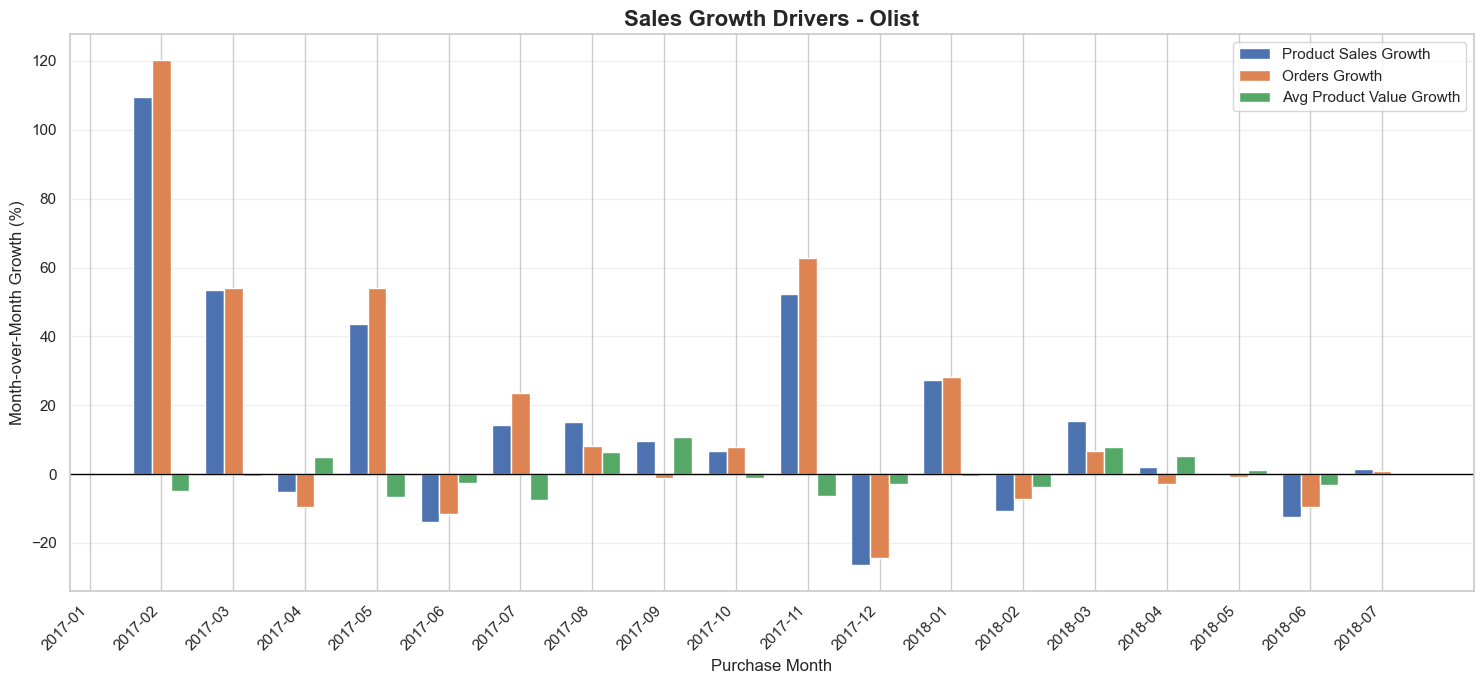

In [55]:

# Prepare chart data
labels = monthly_growth["year_month"].dt.strftime("%Y-%m")
x = np.arange(len(labels))
width = 0.26

fig, ax = plt.subplots(figsize=(15, 7))

# Sales growth
ax.bar(
    x - width,
    monthly_growth["sales_growth_pct"],
    width,
    label="Product Sales Growth"
)

# Order growth
ax.bar(
    x,
    monthly_growth["orders_growth_pct"],
    width,
    label="Orders Growth"
)

# Average product value growth
ax.bar(
    x + width,
    monthly_growth["avg_product_growth_pct"],
    width,
    label="Avg Product Value Growth"
)

ax.axhline(0, color="black", linewidth=1)

ax.set_title(
    "Sales Growth Drivers - Olist",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Purchase Month")
ax.set_ylabel("Month-over-Month Growth (%)")

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Sales interpretation.** Historical delivered-order product value totals **R$ 13,221,498.11**, with an additional **R$ 2,198,275.64** in freight. Mean delivered-order value including freight is **R$ 159.83**. Monthly growth is a descriptive time-series comparison, not a forecast.

## 9. Product-Category Performance

Join delivered line items with product-category labels and optional English translations. Preserve the original Portuguese label when a translation is unavailable; use `Unknown` if the original label is missing.

In [56]:
# Load product datasets
products = datasets["olist_products_dataset"].copy()

categories = datasets[
    "product_category_name_translation"
].copy()

# Select delivered orders
delivered_ids = orders.loc[
    orders["order_status"] == "delivered",
    ["order_id"]
]

# Keep items from delivered orders
delivered_items = order_items.merge(
    delivered_ids,
    on="order_id",
    how="inner",
    validate="many_to_one"
)

# Join product information
sales_items = delivered_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Join category translations
sales_items = sales_items.merge(
    categories,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

# Handle missing translations
sales_items["category"] = (
    sales_items["product_category_name_english"]
    .fillna(sales_items["product_category_name"])
    .fillna("Unknown")
)

# Validate results
print("Original Delivered Items:", len(delivered_items))
print("Items After JOIN:", len(sales_items))
print("Unique Categories:", sales_items["category"].nunique())

print(
    "Items Without Category:",
    (sales_items["category"] == "Unknown").sum()
)

print(
    "Product Value Preserved:",
    abs(sales_items["price"].sum() - total_product_sales) < 0.01
)

display(sales_items.head())

Original Delivered Items: 110197
Items After JOIN: 110197
Unique Categories: 74
Items Without Category: 1537
Product Value Preserved: True


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english,category
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools,garden_tools


### 9.1 Highest-value product categories

In [57]:
# Product Category Performance

category_performance = (
    sales_items
    .groupby("category")
    .agg(
        total_items=("product_id", "count"),
        total_orders=("order_id", "nunique"),
        product_sales=("price", "sum"),
        avg_item_price=("price", "mean")
    )
    .reset_index()
)

# Calculate sales share
category_performance["sales_share_pct"] = (
    category_performance["product_sales"] /
    category_performance["product_sales"].sum()
) * 100

# Sort by product sales
category_performance = category_performance.sort_values(
    "product_sales",
    ascending=False
)

# Top 10 categories
top_categories = category_performance.head(10)

display(top_categories.round(2))

,category,total_items,total_orders,product_sales,avg_item_price,sales_share_pct
44,health_beauty,9465,8647,1233131.72,130.28,9.33
73,watches_gifts,5859,5495,1166176.98,199.04,8.82
8,bed_bath_table,10953,9272,1023434.76,93.44,7.74
68,sports_leisure,8431,7530,954852.55,113.25,7.22
16,computers_accessories,7644,6530,888724.61,116.26,6.72
40,furniture_decor,8160,6307,711927.69,87.25,5.38
50,housewares,6795,5743,615628.69,90.60,4.66
21,cool_stuff,3718,3559,610204.10,164.12,4.62
6,auto,4140,3810,578966.65,139.85,4.38
72,toys,4030,3804,471286.48,116.94,3.56


### 9.2 Category coverage and missing translations

Distinguish items without an original category from those with a Portuguese category but no English translation. Unclassified items remain in product-value totals.


In [ ]:

# Prepare Top 10 Categories
top_categories_plot = top_categories.copy()

# Format category names
top_categories_plot["category_label"] = (
    top_categories_plot["category"]
    .str.replace("_", " ", regex=False)
    .str.title()
)

# Create chart
plt.figure(figsize=(13, 7))

ax = sns.barplot(
    data=top_categories_plot,
    x="product_sales",
    y="category_label",
    color="steelblue"
)

# Add value labels
for bar in ax.patches:
    width = bar.get_width()

    ax.annotate(
        f"R$ {width / 1_000_000:.2f}M",
        (
            width,
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=10
    )

# Labels
plt.title(
    "Top 10 Product Categories by Sales Value - Olist",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Product Sales (BRL)")
plt.ylabel("Product Category")

plt.xlim(
    0,
    top_categories_plot["product_sales"].max() * 1.22
)

plt.tight_layout()

# Save for GitHub portfolio
plt.savefig(
    figures_path / "top_product_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Distinguish missing original product categories from untranslated labels.
missing_original = sales_items["product_category_name"].isna()
missing_translation = sales_items["product_category_name_english"].isna()
untranslated_items = sales_items[~missing_original & missing_translation].copy()
unknown_items = sales_items[sales_items["category"] == "Unknown"]

print("=== CATEGORY COVERAGE VALIDATION ===")
print("Missing original categories:", missing_original.sum())
print("Missing English translations:", missing_translation.sum())
print("Items with a Portuguese label but no English translation:", len(untranslated_items))
print("Items classified as Unknown:", len(unknown_items))
print("Unique products without a category:", unknown_items["product_id"].nunique())
print("Unclassified product value (BRL):", round(unknown_items["price"].sum(), 2))
print("Unclassified product value share (%):", round(unknown_items["price"].sum() / sales_items["price"].sum() * 100, 2))
display(untranslated_items["product_category_name"].value_counts())


**Category data-quality note.** 1,537 delivered line items (about 1.29% of product value) had no original category. Another 22 line items had an original Portuguese label but no English translation. Those 22 retain their original names.

## 10. Power BI Data Model and Export

Create **one row per delivered order** and **one row per delivered line item**. In Power BI, `orders_dashboard[order_id]` is the one-side and `order_items_dashboard[order_id]` is the many-side.

In [61]:
# Executive Dashboard - Consolidated Dataset

# Começar com os pedidos entregues
dashboard_orders = delivered_sales.copy()

# Adicionar identificação do cliente
dashboard_orders = dashboard_orders.merge(
    orders[["order_id", "customer_id"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Adicionar estado do cliente
dashboard_orders = dashboard_orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Adicionar indicadores logísticos
dashboard_orders = dashboard_orders.merge(
    late_delivery[
        ["order_id", "delivery_days", "delay_days", "is_late"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Adicionar avaliações dos clientes
dashboard_orders = dashboard_orders.merge(
    reviews_clean[
        ["order_id", "avg_review_score", "review_count"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Adicionar os pagamentos registrados
dashboard_orders = dashboard_orders.merge(
    payments_summary[
        ["order_id", "payment_total"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Consolidated Dataset Created!")

display(dashboard_orders.head())

Consolidated Dataset Created!


,order_id,order_purchase_timestamp,total_items,product_value,freight_value,items_total,year_month,customer_id,customer_state,delivery_days,delay_days,is_late,avg_review_score,review_count,payment_total
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,1,29.99,8.72,38.71,2017-10,9ef432eb6251297304e76186b10a928d,SP,8.436574,-8.0,False,4.0,1.0,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,1,118.70,22.76,141.46,2018-07,b0830fb4747a6c6d20dea0b8c802d7ef,BA,13.782037,-6.0,False,4.0,1.0,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,1,159.90,19.22,179.12,2018-08,41ce2a54c0b03bf3443c3d931a367089,GO,9.394213,-18.0,False,5.0,1.0,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,1,45.00,27.20,72.20,2017-11,f88197465ea7920adcdbec7375364d82,RN,13.208750,-13.0,False,5.0,1.0,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,1,19.90,8.72,28.62,2018-02,8ab97904e6daea8866dbdbc4fb7aad2c,SP,2.873877,-10.0,False,5.0,1.0,28.62


### 10.1 Consolidated dataset quality checks

Validate uniqueness, null coverage, and conservation of product value.

In [62]:
# Final Consolidated Dataset Validation

print("=== DASHBOARD DATA VALIDATION ===")

print("Total Orders:", len(dashboard_orders))

print(
    "Duplicate Order IDs:",
    dashboard_orders["order_id"].duplicated().sum()
)

print(
    "Orders Without State:",
    dashboard_orders["customer_state"].isna().sum()
)

print(
    "Orders Without Delivery Date:",
    dashboard_orders["delivery_days"].isna().sum()
)

print(
    "Orders Without Reviews:",
    dashboard_orders["avg_review_score"].isna().sum()
)

print(
    "Orders Without Payments:",
    dashboard_orders["payment_total"].isna().sum()
)

print(
    "Product Value Preserved:",
    abs(
        dashboard_orders["product_value"].sum()
        - total_product_sales
    ) < 0.01
)

print("\nDataset Shape:", dashboard_orders.shape)

=== DASHBOARD DATA VALIDATION ===
Total Orders: 96478
Duplicate Order IDs: 0
Orders Without State: 0
Orders Without Delivery Date: 8
Orders Without Reviews: 646
Orders Without Payments: 1
Product Value Preserved: True

Dataset Shape: (96478, 15)


### 10.2 Export processed CSVs

Write `orders_dashboard.csv` and `order_items_dashboard.csv` to `data/processed/`.

In [ ]:

# Create export directory
export_path = project_root / "data" / "processed"

export_path.mkdir(parents=True, exist_ok=True)

# Orders dataset
orders_export = dashboard_orders.copy()

# Format Year-Month
orders_export["year_month"] = (
    orders_export["order_purchase_timestamp"]
    .dt.strftime("%Y-%m")
)

# Order Items dataset
items_export = sales_items[
    [
        "order_id",
        "order_item_id",
        "product_id",
        "seller_id",
        "price",
        "freight_value",
        "category"
    ]
].copy()

# Export to CSV
orders_export.to_csv(
    export_path / "orders_dashboard.csv",
    index=False,
    encoding="utf-8-sig"
)

items_export.to_csv(
    export_path / "order_items_dashboard.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Datasets exported successfully!")
print("Location:", export_path)

### 10.3 Re-import and verify processed exports

Check row counts, order uniqueness and total product value across both outputs.

In [64]:
# Reload exported datasets
orders_check = pd.read_csv(
    export_path / "orders_dashboard.csv"
)

items_check = pd.read_csv(
    export_path / "order_items_dashboard.csv"
)

print("=== EXPORT VALIDATION ===")

print("Orders:", orders_check.shape)
print("Items:", items_check.shape)

print(
    "Duplicate Orders:",
    orders_check["order_id"].duplicated().sum()
)

print(
    "Product Values Match:",
    abs(
        orders_check["product_value"].sum()
        - items_check["price"].sum()
    ) < 0.01
)

=== EXPORT VALIDATION ===
Orders: (96478, 15)
Items: (110197, 7)
Duplicate Orders: 0
Product Values Match: True


## 11. Executive Findings and Recommendations

**Key findings**
1. Delivered-order product value: R$ 13.22 million across 96,478 orders.
2. Late deliveries accounted for 6.77% of the 96,470 shipments with calculable delivery times.
3. The average review score was lower for late shipments (2.27 versus 4.29).
4. Geographic comparisons depend on whether the priority is delay volume or delay rate.

**Practical recommendations**
- Investigate high-volume late deliveries in SP and RJ.
- Compare carrier operations and estimated transit windows in states with elevated delay rates.
- Prioritize proactive status notifications for shipments at risk of arriving late.
- Monitor delivery delays and post-delivery review metrics together.

**Limitations**
- This historical public dataset does not represent current operations.
- Delays and poor reviews are associated; this analysis does not establish causation.
- Some delivered orders lack valid delivery dates, reviews, or payments.
- Rating data are aggregated by order; individual review differences are retained only in audit outputs.
- Reproducibility evidence: on October 26, 2026, the project owner reported running all cells locally using the original CSVs. A screenshot of the export-validation output confirmed 96,478 orders, 110,197 item rows, zero duplicate order IDs, and matching aggregated product values. The shared notebook still includes saved results from an earlier recorded run; the packaged version has not been independently re-executed here because the raw CSVs were not uploaded.
